# TUẦN 3 (BUỔI 3) — BÀI 2: PHÂN LOẠI WINE QUALITY
**Đặng Văn Chung — 24174800194 — DHKM18A2HN**

## 1. Chuẩn bị
### Bước 1. Kiểm tra thư viện sampling

In [ ]:
import os
import sys
import subprocess
import importlib.util

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
if importlib.util.find_spec("imblearn") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])

### Bước 2. Import thư viện dữ liệu và mô hình

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

### Bước 3. Import sampling và công cụ đánh giá

In [ ]:
from sklearn.dummy import DummyClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.expand_frame_repr", False)

## 2. Kiểm tra dữ liệu
### Bước 1. Chọn tệp CSV

In [ ]:
csv_path = Path("wine_quality_merged.csv")
if not csv_path.exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("Đặt wine_quality_merged.csv cùng thư mục làm việc.")
if not csv_path.exists():
    raise FileNotFoundError("Chưa tìm thấy wine_quality_merged.csv.")

### Bước 2. Đọc và xem dữ liệu

In [ ]:
wine_raw = pd.read_csv(csv_path)
print("Kích thước:", wine_raw.shape)
display(wine_raw.head())

Kích thước: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


### Bước 3. Kiểm tra thiếu, trùng và các mức quality

In [ ]:
print("Số giá trị thiếu:", int(wine_raw.isna().sum().sum()))
print("Số dòng trùng hoàn toàn:", int(wine_raw.duplicated().sum()))
print("Loại rượu:", wine_raw["type"].value_counts().to_dict())
display(wine_raw["quality"].value_counts().sort_index().to_frame("Số mẫu"))

Số giá trị thiếu: 0
Số dòng trùng hoàn toàn: 1177
Loại rượu: {'white': 4898, 'red': 1599}


,Số mẫu
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


### Bước 4. Loại các dòng trùng hoàn toàn
Chỉ giữ một bản của mỗi dòng trước khi chia tập, tránh bản sao xuất hiện ở cả Train và Test.

In [ ]:
wine = wine_raw.drop_duplicates().reset_index(drop=True)
print("Sau loại trùng:", wine.shape)
print("Đã loại:", len(wine_raw) - len(wine), "dòng")

Sau loại trùng: (5320, 13)
Đã loại: 1177 dòng


### Bước 5. Tạo nhãn và xem tỷ lệ lớp

In [ ]:
wine["target"] = (wine["quality"] >= 7).astype(int)
class_table = wine["target"].value_counts().sort_index().to_frame("Số mẫu")
class_table["Tỷ lệ (%)"] = class_table["Số mẫu"] / len(wine) * 100
class_table.index = ["Chưa tốt (0)", "Tốt (1)"]
display(class_table.round(2))

,Số mẫu,Tỷ lệ (%)
Chưa tốt (0),4311,81.03
Tốt (1),1009,18.97


**Nhận xét dữ liệu:** sau loại 1.177 dòng trùng, còn 5.320 mẫu: 4.311 chưa tốt (81,03%) và 1.009 tốt (18,97%). Lớp tốt là lớp thiểu số. Không có giá trị thiếu.

## 3. Chuẩn bị Train/Test
### Bước 1. Tách đầu vào và mã hóa type
Loại cả `quality` và `target` khỏi X. Mã hóa cố định `red=0`, `white=1`; đây không phải phép biến đổi cần học thống kê.

In [ ]:
X = wine.drop(columns=["quality", "target"]).copy()
y = wine["target"].copy()
X["type"] = X["type"].map({"red": 0, "white": 1})
assert X["type"].notna().all(), "Có giá trị type chưa được khai báo."
print("X:", X.shape, "; y:", y.shape)

X: (5320, 12) ; y: (5320,)


### Bước 2. Kiểm tra đầu vào còn trùng sau loại quality không

In [ ]:
print("Số dòng X trùng nhau:", int(X.duplicated().sum()))
assert not X.duplicated().any(), "Cần chia theo nhóm nếu các dòng đầu vào còn trùng."

Số dòng X trùng nhau: 0


### Bước 3. Chia Train/Test có stratify

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, y_train.value_counts().sort_index().to_dict())
print("Test:", X_test.shape, y_test.value_counts().sort_index().to_dict())

Train: (4256, 12) {0: 3449, 1: 807}
Test: (1064, 12) {0: 862, 1: 202}


### Bước 4. Cố định 5 fold trên Train

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds5 = list(cv.split(X_train, y_train))

## 4. Tạo pipeline dùng chung
### Bước 1. Chuẩn hóa 11 cột số, giữ type ở cột cuối
Dữ liệu đã kiểm tra không có giá trị thiếu. Scaler chỉ được fit trên phần Train của mỗi fold.

In [ ]:
numeric_cols = X.columns.drop("type").tolist()
preprocess = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_cols),
    ("type", "passthrough", ["type"])
])
print("Số cột số:", len(numeric_cols), "; vị trí type sau biến đổi:", len(numeric_cols))

Số cột số: 11 ; vị trí type sau biến đổi: 11


### Bước 2. Tạo hàm ghép tiền xử lý, sampling và classifier

In [ ]:
def build_pipeline(model=None, sampler=None):
    if model is None:
        model = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    steps = [("preprocess", clone(preprocess))]
    if sampler is not None:
        steps.append(("sampler", clone(sampler)))
    steps.append(("model", clone(model)))
    return Pipeline(steps)

### Bước 3. Khai báo các chỉ số CV

In [ ]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

### Bước 4. Tạo hàm chạy CV và tính mean/std

In [ ]:
def evaluate_cv(pipe):
    scores = cross_validate(
        pipe, X_train, y_train, cv=folds5, scoring=scoring,
        n_jobs=1, error_score="raise"
    )
    row = {}
    for metric in scoring:
        values = scores["test_" + metric]
        row[metric + "_mean"] = values.mean()
        row[metric + "_std"] = values.std(ddof=1)
    return row

### Bước 5. Tạo hàm trình bày bảng

In [ ]:
def show_scores(results):
    table = pd.DataFrame(index=results.index)
    for metric in scoring:
        table[metric + " (mean ± std)"] = results.apply(
            lambda r: f"{r[metric + '_mean']:.4f} ± {r[metric + '_std']:.4f}", axis=1
        )
    display(table)

## 5. So sánh sampling với Logistic Regression
### Bước 1. Tạo các sampler
Dùng **SMOTENC** thay SMOTE thông thường để xử lý cột phân loại `type`; 11 cột liên tục đã được scale, type không được nội suy thành giá trị như 0.3 hoặc 0.7.

In [ ]:
samplers = {
    "Không sampling": None,
    "ROS": RandomOverSampler(random_state=RANDOM_STATE),
    "RUS": RandomUnderSampler(random_state=RANDOM_STATE),
    "SMOTENC": SMOTENC(categorical_features=[len(numeric_cols)], random_state=RANDOM_STATE)
}

### Bước 2. Chạy mốc chỉ dự đoán lớp đa số

In [ ]:
dummy = build_pipeline(model=DummyClassifier(strategy="most_frequent"))
dummy_result = pd.DataFrame([evaluate_cv(dummy)], index=["Dummy"])
show_scores(dummy_result)

,accuracy (mean ± std),precision (mean ± std),recall (mean ± std),f1 (mean ± std),roc_auc (mean ± std),pr_auc (mean ± std)
Dummy,0.8104 ± 0.0006,0.0000 ± 0.0000,0.0000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.1896 ± 0.0006


**Mốc so sánh:** Dummy đạt Accuracy khoảng 0.8104 nhưng Recall và F1 lớp tốt đều bằng 0. Vì vậy, Accuracy cao chưa đủ để chọn mô hình.

### Bước 3. Chạy từng kỹ thuật sampling
Giữ cùng Logistic Regression và cùng folds5.

In [ ]:
rows = []
for name, sampler in samplers.items():
    pipe = build_pipeline(sampler=sampler)
    row = evaluate_cv(pipe)
    rows.append({"Sampling": name, **row})

### Bước 4. Xem bảng kết quả

In [ ]:
sampling_results = pd.DataFrame(rows).set_index("Sampling")
show_scores(sampling_results.sort_values("f1_mean", ascending=False))

,accuracy (mean ± std),precision (mean ± std),recall (mean ± std),f1 (mean ± std),roc_auc (mean ± std),pr_auc (mean ± std)
Sampling,,,,,,
RUS,0.7394 ± 0.0128,0.4043 ± 0.0161,0.7893 ± 0.0372,0.5346 ± 0.0207,0.8287 ± 0.0138,0.5184 ± 0.0236
SMOTENC,0.7439 ± 0.0155,0.4080 ± 0.0183,0.7720 ± 0.0387,0.5335 ± 0.0190,0.8304 ± 0.0151,0.5217 ± 0.0243
ROS,0.7399 ± 0.0170,0.4043 ± 0.0204,0.7794 ± 0.0393,0.5321 ± 0.0221,0.8303 ± 0.0144,0.5228 ± 0.0249
Không sampling,0.8280 ± 0.0074,0.5926 ± 0.0489,0.3086 ± 0.0213,0.4047 ± 0.0183,0.8316 ± 0.0146,0.5263 ± 0.0242


**Nhận xét sampling:** không sampling có Accuracy 0.8280 nhưng Recall chỉ 0.3086. ROS, RUS và SMOTENC tăng Recall lên khoảng 0.77–0.79, đồng thời Precision giảm. RUS có F1 cao nhất 0.5346, chỉ nhỉnh hơn SMOTENC 0.5335; đây là thứ hạng của phép chia hiện tại, không chứng minh ưu thế ổn định. AP không được cải thiện so với không sampling.

### Bước 5. Chọn sampler theo F1 CV

In [ ]:
best_sampling = sampling_results["f1_mean"].idxmax()
print("Sampling được chọn:", best_sampling)

Sampling được chọn: RUS


## 6. So sánh classifier
### Bước 1. Khai báo mô hình
Giữ sampler vừa chọn; chỉ thay classifier. Đây là cách chọn lần lượt, không vét cạn mọi tổ hợp sampler–classifier.

In [ ]:
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM-RBF": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE)
}

### Bước 2. Chạy CV với cùng tiền xử lý và sampling

In [ ]:
rows = []
for name, model in classifiers.items():
    pipe = build_pipeline(model=model, sampler=samplers[best_sampling])
    row = evaluate_cv(pipe)
    rows.append({"Classifier": name, **row})

### Bước 3. Xem bảng so sánh

In [ ]:
classifier_results = pd.DataFrame(rows).set_index("Classifier")
show_scores(classifier_results.sort_values("f1_mean", ascending=False))

,accuracy (mean ± std),precision (mean ± std),recall (mean ± std),f1 (mean ± std),roc_auc (mean ± std),pr_auc (mean ± std)
Classifier,,,,,,
SVM-RBF,0.7340 ± 0.0145,0.4024 ± 0.0166,0.8265 ± 0.0154,0.5412 ± 0.0170,0.8385 ± 0.0097,0.5295 ± 0.0300
Logistic Regression,0.7394 ± 0.0128,0.4043 ± 0.0161,0.7893 ± 0.0372,0.5346 ± 0.0207,0.8287 ± 0.0138,0.5184 ± 0.0236
KNN,0.6927 ± 0.0142,0.3589 ± 0.0114,0.7869 ± 0.0112,0.4928 ± 0.0090,0.7953 ± 0.0086,0.4095 ± 0.0206
Decision Tree,0.6844 ± 0.0248,0.3497 ± 0.0190,0.7659 ± 0.0477,0.4795 ± 0.0188,0.7457 ± 0.0230,0.3633 ± 0.0287


**Nhận xét classifier:** với cùng RUS, SVM-RBF có F1 CV cao nhất 0.5412, Recall 0.8265 và AP 0.5295. Logistic Regression đứng tiếp theo về F1 (0.5346). Chọn SVM-RBF theo F1 CV rồi mới đánh giá Test.

### Bước 4. Chọn classifier theo F1 CV

In [ ]:
best_classifier = classifier_results["f1_mean"].idxmax()
print("Classifier:", best_classifier)
print("Sampling:", best_sampling)

Classifier: SVM-RBF
Sampling: RUS


## 7. Đánh giá cuối trên Test
### Bước 1. Fit pipeline đã chọn trên toàn bộ Train

In [ ]:
final_model = build_pipeline(
    model=classifiers[best_classifier], sampler=samplers[best_sampling]
)
final_model.fit(X_train, y_train)
print("Đã huấn luyện:", best_classifier, "+", best_sampling)

Đã huấn luyện: SVM-RBF + RUS


### Bước 2. Dự đoán nhãn và điểm liên tục trên Test
SVM dùng decision_function; các mô hình còn lại dùng xác suất lớp 1 để tính ROC-AUC và AP.

In [ ]:
y_pred = final_model.predict(X_test)
if hasattr(final_model, "predict_proba"):
    y_score = final_model.predict_proba(X_test)[:, 1]
else:
    y_score = final_model.decision_function(X_test)

### Bước 3. In các chỉ số Test

In [ ]:
test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_score),
    "AP (PR-AUC)": average_precision_score(y_test, y_score)
}, name="Test")
display(test_metrics.round(4))

Accuracy       0.7265
Precision      0.3953
Recall         0.8317
F1             0.5359
ROC-AUC        0.8464
AP (PR-AUC)    0.5025
Name: Test, dtype: float64

### Bước 4. Vẽ Confusion Matrix

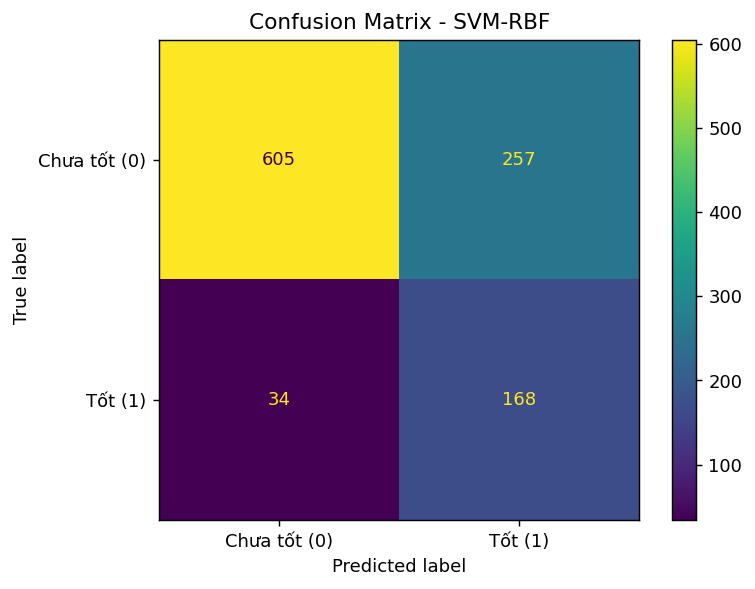

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Chưa tốt (0)", "Tốt (1)"]
)
plt.title("Confusion Matrix - " + best_classifier)
plt.show()

### Bước 5. In Classification Report

In [ ]:
print(classification_report(
    y_test, y_pred, target_names=["Chưa tốt (0)", "Tốt (1)"],
    digits=4, zero_division=0
))

              precision    recall  f1-score   support

Chưa tốt (0)     0.9468    0.7019    0.8061       862
     Tốt (1)     0.3953    0.8317    0.5359       202

    accuracy                         0.7265      1064
   macro avg     0.6710    0.7668    0.6710      1064
weighted avg     0.8421    0.7265    0.7548      1064



### Bước 6. Vẽ Precision–Recall Curve

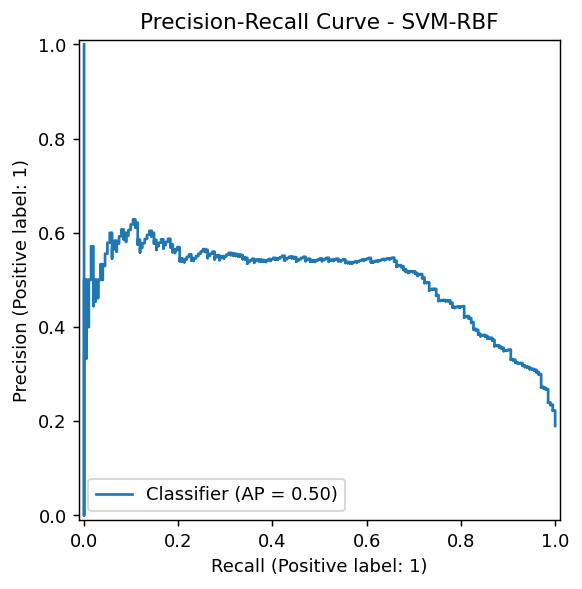

In [ ]:
PrecisionRecallDisplay.from_predictions(y_test, y_score)
plt.title("Precision-Recall Curve - " + best_classifier)
plt.show()

## Kết luận
- Dữ liệu được loại trùng trước khi chia; `quality` không nằm trong đầu vào. Scaler và sampling được học riêng trong từng fold.
- Theo cách chọn lần lượt bằng F1 CV, pipeline cuối là **StandardScaler cho cột số + RUS + SVM-RBF**. Cột type được mã hóa cố định và giữ riêng.
- Trên Test: Accuracy **0.7265**, Precision **0.3953**, Recall **0.8317**, F1 **0.5359**, ROC-AUC **0.8464**, AP **0.5025**.
- Ma trận nhầm lẫn: 605 mẫu chưa tốt và 168 mẫu tốt được nhận diện đúng; 257 mẫu chưa tốt bị báo nhầm là tốt, 34 mẫu tốt bị bỏ sót. Recall cao nhưng Precision còn thấp; không kết luận mô hình tốt chỉ dựa vào một chỉ số. Kết quả áp dụng cho ngưỡng quality >= 7 và các cấu hình đã thử.